# Matriz de pesos espaciais

**Curso de Econometria Espacial**  
Prof. Pedro Amaral · Cedeplar/UFMG  

Dados: *Chicago Health* (Community Areas, ACS 2014) via `libpysal.examples`.


## 1. Importações

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import libpysal 

## 2. Dados: Chicago Health

In [2]:
# Carrega o exemplo e lista os arquivos disponíveis
chicago = libpysal.examples.load_example('Chicago Health')
chicago.get_file_list()


['/Users/pedro/Library/Application Support/pysal/Chicago_Health/ComArea_ACS14_f.prj',
 '/Users/pedro/Library/Application Support/pysal/Chicago_Health/__MACOSX/._ComArea_ACS14_f.prj',
 '/Users/pedro/Library/Application Support/pysal/Chicago_Health/__MACOSX/._ComArea_ACS14_f.shp',
 '/Users/pedro/Library/Application Support/pysal/Chicago_Health/__MACOSX/._ComArea_ACS14_f.shx',
 '/Users/pedro/Library/Application Support/pysal/Chicago_Health/__MACOSX/._ComArea_ACS14_f.dbf',
 '/Users/pedro/Library/Application Support/pysal/Chicago_Health/ComArea_ACS14_f.shx',
 '/Users/pedro/Library/Application Support/pysal/Chicago_Health/ComArea_ACS14_f.shp',
 '/Users/pedro/Library/Application Support/pysal/Chicago_Health/ComArea_ACS14_f.dbf']

In [3]:
# Lê o shapefile das Community Areas
gdf = gpd.read_file(libpysal.examples.get_path('ComArea_ACS14_f.shp'))
print(gdf.shape)
gdf.head()


(77, 87)


,ComAreaID,community,TRACTCnt,shape_area,shape_len,Pop2012,Pop2014,PopChng,PopM,PopMP,...,InfntMR,LungCancer,ProstateC,Stroke,ChlBLLS,ChlLeadP,GonorrF,GonorrM,Tuberc,geometry
0,35,DOUGLAS,10,4.600462e+07,31027.054510,18238,19430,3.1645,8294,42.6866,...,13.4,74.5,85.5,62.1,482.2,0,1063.3,727.4,4.2,"POLYGON ((-87.60914 41.84469, -87.60915 41.844..."
1,36,OAKLAND,3,1.691396e+07,19565.506153,5918,6473,4.4791,2499,38.6065,...,8.2,54.5,54.2,43.7,435.4,0,1655.4,1629.3,6.7,"POLYGON ((-87.59215 41.81693, -87.59231 41.816..."
2,37,FULLER PARK,2,1.991670e+07,25339.089750,2876,2543,-6.1450,1218,47.8962,...,22.6,89.6,70.5,82.4,489.9,2,1061.9,1556.4,0.0,"POLYGON ((-87.6288 41.80189, -87.62879 41.8017..."
3,38,GRAND BOULEVARD,14,4.849250e+07,28196.837157,21929,22531,1.3540,9681,42.9675,...,12.1,63.8,39.0,46.7,590.4,1,1454.6,1680.0,13.2,"POLYGON ((-87.60671 41.81681, -87.6067 41.8165..."
4,39,KENWOOD,7,2.907174e+07,23325.167906,17841,18217,1.0428,8543,46.8958,...,8.9,49.1,46.2,31.5,397.9,0,610.2,549.1,0.0,"POLYGON ((-87.59215 41.81693, -87.59215 41.816..."


## Projeção de dados

O shapefile *Chicago Health* vem em coordenadas **geográficas** (WGS84): latitude e longitude em **graus**. Isso é excelente para localizar pontos no globo, mas inadequado para calcular **distâncias**.

### Graus não são metros

Na superfície da Terra:
- 1° de latitude ≈ 111 km em qualquer lugar;
- 1° de longitude ≈ 111 km no equador, mas apenas ≈ 82 km na latitude de Chicago (~42°N).

A “distância euclidiana” entre dois pontos em graus **não corresponde** à distância real no solo e ainda **varia com a latitude**. Qualquer matriz de pesos baseada em distância (distance band, *k*-NN por distância, inverso da distância etc.) calculada em graus fica geometricamente distorcida.

### O que a projeção resolve

Uma **projeção cartográfica** transforma coordenadas geográficas (graus) em coordenadas planas (metros ou pés), de modo que distâncias e áreas no mapa se aproximem das distâncias e áreas reais *na região de interesse*.

Para Chicago, o fuso adequado é o **UTM 16 Norte** (longitudes entre 90°W e 84°W). O método `gdf.estimate_utm_crs()` informa uma opção com base na longitude do centróide.

### Quando é obrigatório projetar?

| Tipo de matriz                         | Precisa projetar?      |
|----------------------------------------|------------------------|
| Contiguidade (Rainha, Torre)           | Não (usa só topologia) |
| *k* vizinhos mais próximos             | **Sim**                |
| Distance band / funções de distância   | **Sim**                |
| Block weights, fluxos, redes           | Depende da definição   |

### Regra prática

- Se o critério de vizinhança envolve **distância**, trabalhe em metros.  
- Se envolve apenas **fronteira compartilhada**, a projeção é opcional.

No restante deste notebook projetamos o `GeoDataFrame` para UTM 16N *antes* de construir as matrizes, para que distância crítica, *k*-NN e distance band tenham interpretação física correta.

In [4]:
print(gdf.crs)
gdf.estimate_utm_crs()

GEOGCS["WGS84(DD)",DATUM["WGS_1984",SPHEROID["WGS84",6378137,298.257223563],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433],AXIS["Longitude",EAST],AXIS["Latitude",NORTH]]


<Projected CRS: EPSG:32616>
Name: WGS 84 / UTM zone 16N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 90°W and 84°W, northern hemisphere between equator and 84°N, onshore and offshore. Belize. Canada - Manitoba; Nunavut; Ontario. Costa Rica. Cuba. Ecuador - Galapagos. El Salvador. Guatemala. Honduras. Mexico. Nicaragua. United States (USA).
- bounds: (-90.0, 0.0, -84.0, 84.0)
Coordinate Operation:
- name: UTM zone 16N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [5]:
# Projeta para UTM 16N (metros) — necessário para matrizes baseadas em distância
gdf = gdf.to_crs(epsg=32616)
print(gdf.crs)


EPSG:32616


## 3. Matriz Rainha (*Queen*)

In [6]:
w_queen = libpysal.weights.Queen.from_dataframe(gdf, use_index=False)
print(w_queen.n, 'observações')

77 observações


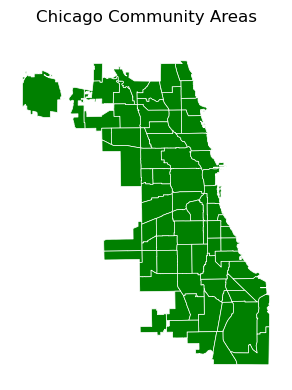

In [7]:
# Mapa temático base (apenas geografia)
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
gdf.plot(ax=ax, facecolor='green', edgecolor='white', linewidth=0.5)
ax.set_title('Chicago Community Areas')
ax.set_axis_off()
plt.tight_layout()
plt.show()


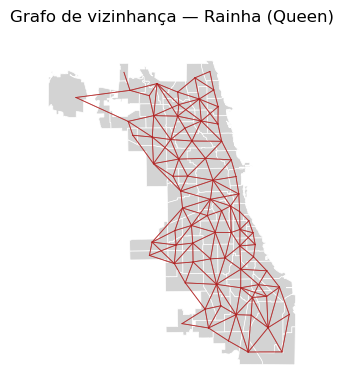

In [8]:
# Grafo de vizinhança sobre o mapa
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
gdf.plot(ax=ax, facecolor='lightgray', edgecolor='white', linewidth=0.5)
w_queen.plot(gdf, ax=ax, edge_kws=dict(color='firebrick', linewidth=0.6, alpha=0.7),
             node_kws=dict(marker=''))
ax.set_title('Grafo de vizinhança — Rainha (Queen)')
ax.set_axis_off()
plt.tight_layout()
plt.show()


### Atributos da matriz Rainha

In [9]:
def weights_summary(w, name='W'):
    """Retorna um DataFrame com estatísticas descritivas da matriz de pesos."""
    n = w.n
    card = pd.Series(w.cardinalities)
    return pd.DataFrame({
        'matriz': [name],
        'observations': [n],
        'min_neighbors': [int(card.min())],
        'max_neighbors': [int(card.max())],
        'mean_neighbors': [round(card.mean(), 2)],
        'median_neighbors': [int(card.median())],
        'pct_nonzero': [round(w.pct_nonzero, 2)],
        'islands': [len(w.islands)],
    })

summary_queen = weights_summary(w_queen, 'Queen')
summary_queen


,matriz,observations,min_neighbors,max_neighbors,mean_neighbors,median_neighbors,pct_nonzero,islands
0,Queen,77,1,9,5.12,5,6.65,0


### Histograma do número de vizinhos (Rainha)

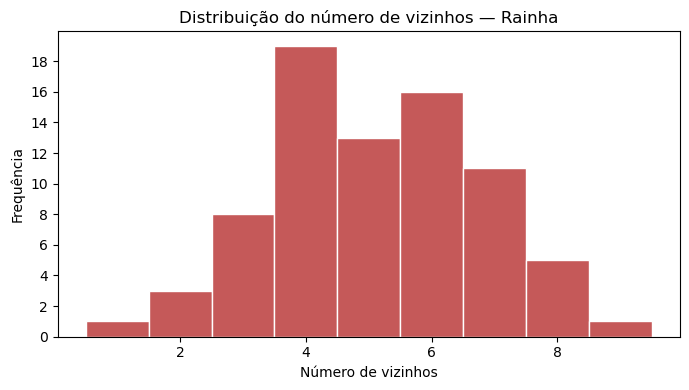

In [10]:
card_queen = pd.Series(w_queen.cardinalities, name='n_vizinhos')

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(card_queen, bins=range(card_queen.min(), card_queen.max() + 2),
             discrete=True, color='firebrick', edgecolor='white', ax=ax)
ax.set_xlabel('Número de vizinhos')
ax.set_ylabel('Frequência')
ax.set_title('Distribuição do número de vizinhos — Rainha')
ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

## 4. Matriz de 5 vizinhos mais próximos (*k*-NN)

In [11]:
w_knn = libpysal.weights.KNN.from_dataframe(gdf, k=5, use_index=False)

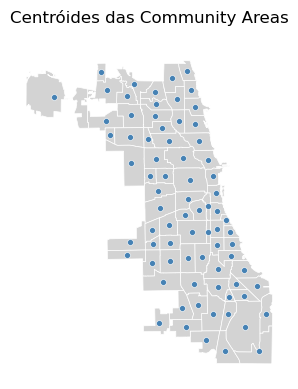

In [12]:
# Centróides
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
gdf.plot(ax=ax, facecolor='lightgray', edgecolor='white', linewidth=0.5)

centroids = gdf.geometry.centroid
ax.scatter(centroids.x, centroids.y, c='steelblue', s=18,
           edgecolor='white', linewidth=0.4, zorder=3)

ax.set_title('Centróides das Community Areas')
ax.set_axis_off()
plt.tight_layout()
plt.show()

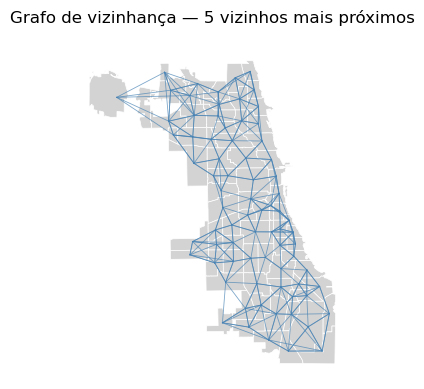

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
gdf.plot(ax=ax, facecolor='lightgray', edgecolor='white', linewidth=0.5)
w_knn.plot(gdf, ax=ax, edge_kws=dict(color='steelblue', linewidth=0.6, alpha=0.7),
           node_kws=dict(marker=''))
ax.set_title('Grafo de vizinhança — 5 vizinhos mais próximos')
ax.set_axis_off()
plt.tight_layout()
plt.show()


In [14]:
summary_knn = weights_summary(w_knn, 'KNN-5')
summary_knn

,matriz,observations,min_neighbors,max_neighbors,mean_neighbors,median_neighbors,pct_nonzero,islands
0,KNN-5,77,5,5,5.0,5,6.49,0


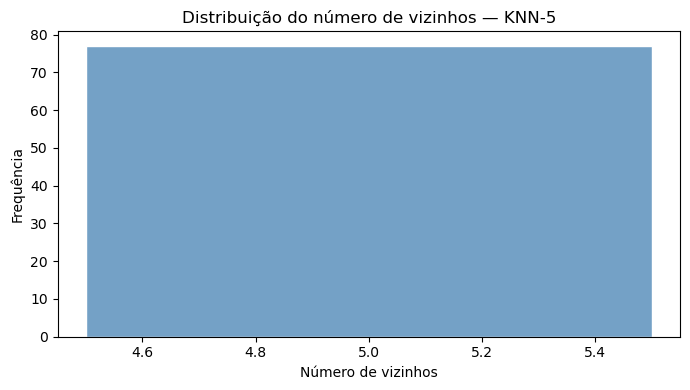

In [15]:
card_knn = pd.Series(w_knn.cardinalities, name='n_vizinhos')

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(card_knn, bins=range(card_knn.min(), card_knn.max() + 2),
             discrete=True, color='steelblue', edgecolor='white', ax=ax)
ax.set_xlabel('Número de vizinhos')
ax.set_ylabel('Frequência')
ax.set_title('Distribuição do número de vizinhos — KNN-5')
plt.tight_layout()
plt.show()


## 5. Matriz de distância (*Distance Band*)

Usamos o **limite crítico de distância** (menor raio que garante que todas as unidades tenham ao menos 1 vizinho), arredondado para cima: **8 km**.


In [16]:
# Coordenadas dos centróides (já em metros)
coords = np.column_stack([gdf.centroid.x, gdf.centroid.y])
d_critico = libpysal.weights.util.min_threshold_distance(coords)
print(f'Distância crítica mínima: {d_critico:,.0f} m ({d_critico/1000:.2f} km)')

# Usamos 8 km (garante conectividade)
threshold = 8000  # metros
w_dist = libpysal.weights.DistanceBand.from_dataframe(gdf, threshold=8000, use_index=False)

Distância crítica mínima: 7,509 m (7.51 km)


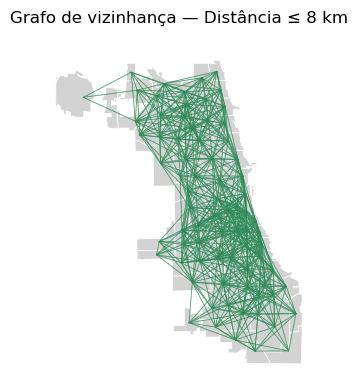

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
gdf.plot(ax=ax, facecolor='lightgray', edgecolor='white', linewidth=0.5)
w_dist.plot(gdf, ax=ax, edge_kws=dict(color='seagreen', linewidth=0.5, alpha=0.6),
            node_kws=dict(marker=''))
ax.set_title(f'Grafo de vizinhança — Distância ≤ {threshold/1000:.0f} km')
ax.set_axis_off()
plt.tight_layout()
plt.show()


In [18]:
summary_dist = weights_summary(w_dist, 'Dist-8km')
summary_dist

,matriz,observations,min_neighbors,max_neighbors,mean_neighbors,median_neighbors,pct_nonzero,islands
0,Dist-8km,77,3,30,18.08,18,23.48,0


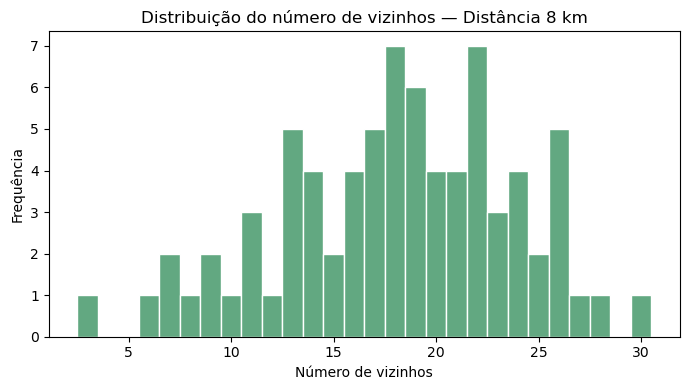

In [19]:
card_dist = pd.Series(w_dist.cardinalities, name='n_vizinhos')

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(card_dist, bins=range(int(card_dist.min()), int(card_dist.max()) + 2),
             discrete=True, color='seagreen', edgecolor='white', ax=ax)
ax.set_xlabel('Número de vizinhos')
ax.set_ylabel('Frequência')
ax.set_title('Distribuição do número de vizinhos — Distância 8 km')
plt.tight_layout()
plt.show()


## 6. Comparação das três matrizes

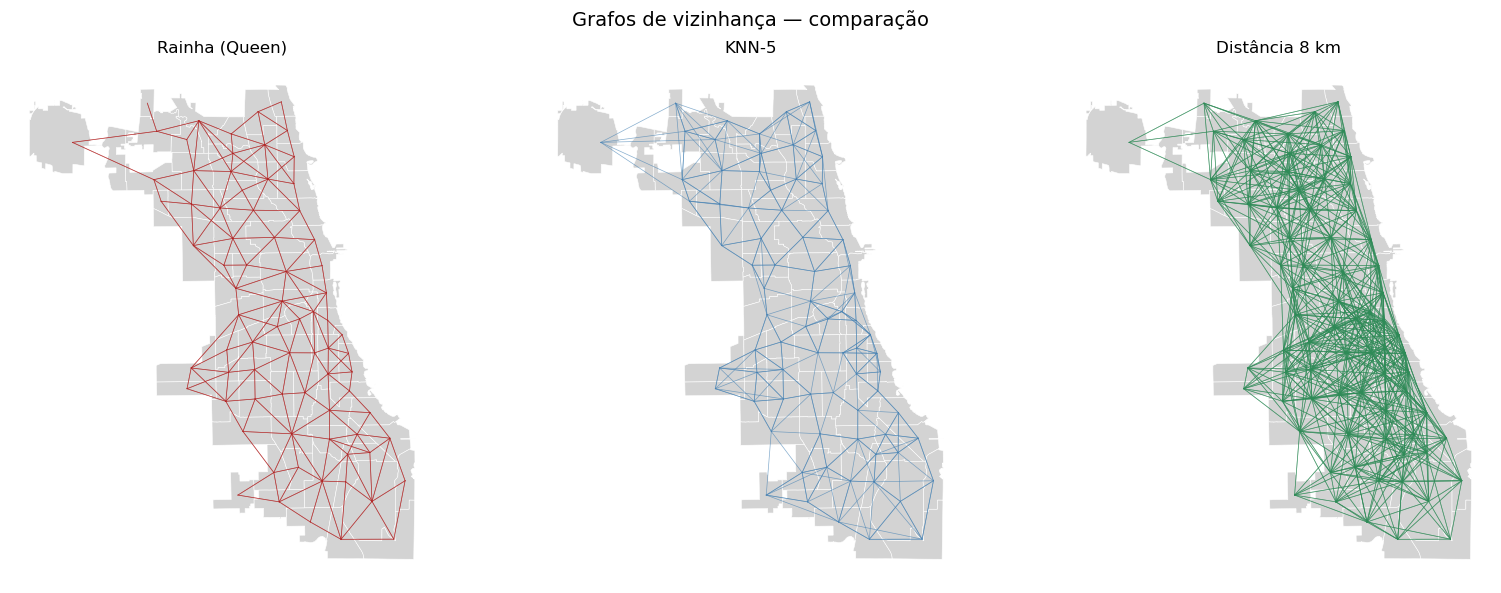

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for ax, w, title, color in zip(
    axes,
    [w_queen, w_knn, w_dist],
    ['Rainha (Queen)', 'KNN-5', 'Distância 8 km'],
    ['firebrick', 'steelblue', 'seagreen'],
):
    gdf.plot(ax=ax, facecolor='lightgray', edgecolor='white', linewidth=0.4)
    w.plot(gdf, ax=ax, edge_kws=dict(color=color, linewidth=0.5, alpha=0.65),
           node_kws=dict(marker=''))
    ax.set_title(title)
    ax.set_axis_off()

plt.suptitle('Grafos de vizinhança — comparação', fontsize=14)
plt.tight_layout()
plt.show()


In [21]:
# Comparação de atributos:
pd.concat([summary_queen, summary_knn, summary_dist], ignore_index=True)

,matriz,observations,min_neighbors,max_neighbors,mean_neighbors,median_neighbors,pct_nonzero,islands
0,Queen,77,1,9,5.12,5,6.65,0
1,KNN-5,77,5,5,5.00,5,6.49,0
2,Dist-8km,77,3,30,18.08,18,23.48,0


---
# Lag Espacial

A **defasagem espacial** de uma variável $y$ é o vetor $\mathbf{Wy}$:
cada observação recebe a média (ou soma, dependendo da padronização de $\mathbf{W}$) dos valores de seus vizinhos.


### Matriz densa

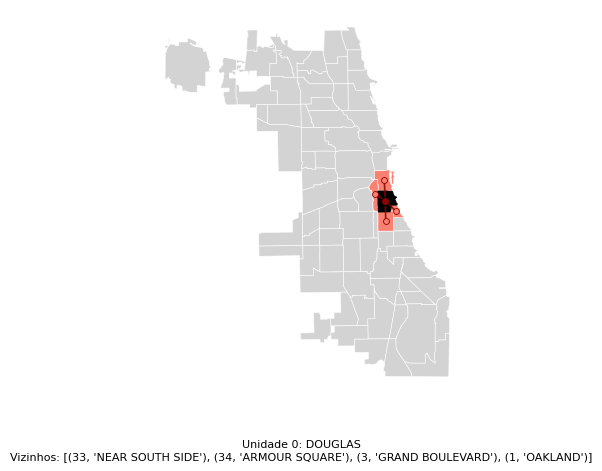

In [22]:
# Unidade correspondente à linha 0 da matriz + grafo local
idx = 0
vizinhos = list(w_queen.neighbors[idx])

fig, ax = plt.subplots(figsize=(5, 5))

gdf.plot(ax=ax, facecolor='lightgray', edgecolor='white', linewidth=0.4)
gdf.iloc[vizinhos].plot(ax=ax, facecolor='salmon', edgecolor='white', linewidth=0.4)
gdf.iloc[[idx]].plot(ax=ax, facecolor='black', edgecolor='black', linewidth=1.2)

centroid = gdf.geometry.centroid
x0, y0 = centroid.iloc[idx].x, centroid.iloc[idx].y
for j in vizinhos:
    xj, yj = centroid.iloc[j].x, centroid.iloc[j].y
    ax.plot([x0, xj], [y0, yj], color='darkred', linewidth=1.2, alpha=0.85, zorder=3)

ax.scatter(centroid.iloc[vizinhos].x, centroid.iloc[vizinhos].y,
           c='salmon', s=18, edgecolor='darkred', linewidth=0.6, zorder=4)
ax.scatter([x0], [y0], c='darkred', s=35, edgecolor='black', linewidth=0.8, zorder=5)

ax.set_axis_off()

fig.text(0.5, 0.02,
         f'Unidade {idx}: {gdf.iloc[idx]["community"]}\n'
         f'Vizinhos: {[(j, gdf.iloc[j]["community"]) for j in vizinhos]}',
         ha='center', va='top', fontsize=8)

plt.show()

In [23]:
# Converte a matriz Rainha para forma densa (full)
w_queen.transform = 'B'  # 'B' = binary
W_full = w_queen.full()[0]  # full() retorna (array, ids)

print('Forma de W:', W_full.shape)
print('\nPrimeiros 5×5 elementos de W (Rainha, binária):')
print(W_full[:5, :5])


Forma de W: (77, 77)

Primeiros 5×5 elementos de W (Rainha, binária):
[[0. 1. 0. 1. 0.]
 [1. 0. 0. 1. 1.]
 [0. 0. 0. 1. 0.]
 [1. 1. 1. 0. 1.]
 [0. 1. 0. 1. 0.]]


### Padronização em linha

In [24]:
# Padronização em linha: cada linha soma 1 → Wy vira média dos vizinhos
w_queen.transform = 'R'  # 'R' = row-standardized
W_row = w_queen.full()[0]

print('Primeiros 5×5 elementos de W (padronizada em linha):')
print(np.round(W_row[:5, :5], 3))
print('\nSoma das linhas (deve ser 1):', W_row[:5].sum(axis=1))


Primeiros 5×5 elementos de W (padronizada em linha):
[[0.    0.25  0.    0.25  0.   ]
 [0.333 0.    0.    0.333 0.333]
 [0.    0.    0.    0.167 0.   ]
 [0.143 0.143 0.143 0.    0.143]
 [0.    0.25  0.    0.25  0.   ]]

Soma das linhas (deve ser 1): [1. 1. 1. 1. 1.]


### Defasagem espacial via multiplicação matricial

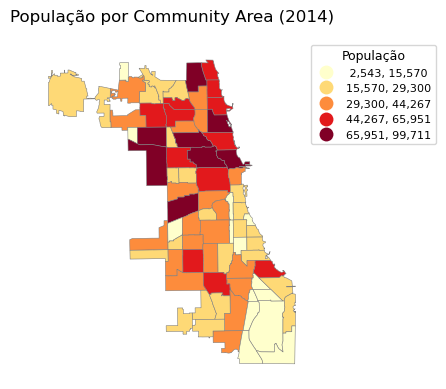

In [25]:
# Mapa de população (Natural Breaks / Fisher-Jenks)
fig, ax = plt.subplots(figsize=(4, 4))
gdf.plot(column='Pop2014', ax=ax, legend=True, cmap='YlOrRd',
         scheme='natural_breaks', k=5,
         edgecolor='grey', linewidth=0.4,
         legend_kwds={
             'title': 'População',
             'loc': 'upper left',
             'bbox_to_anchor': (1.01, 1),
             'borderaxespad': 0,
             'fontsize': 8,
             'title_fontsize': 9,
             'fmt': '{:,.0f}',
         })
ax.set_title('População por Community Area (2014)')
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [26]:
# Wy = W @ y
idx = 0
vizinhos = list(w_queen.neighbors[idx])
w_pop = W_row @ gdf['Pop2014'].values

print(f"Unidade {idx}: {gdf.iloc[idx]['community']}")
print(f"  Pop2014 = {gdf.iloc[idx]['Pop2014']:,.0f}")
print(f"\nVizinhos e Pop2014:")
for j in vizinhos:
    print(f"  {j:>3d}  {gdf.iloc[j]['community']:<20s}  {gdf.iloc[j]['Pop2014']:>8,.0f}")

print(f"\nMédia dos vizinhos = {gdf.iloc[vizinhos]['Pop2014'].mean():,.1f}")
print(f"Wy[{idx}] (via W @ y)  = {w_pop[idx]:,.1f}")

print(f"\nPrimeiros 5 valores de Pop2014:     {np.round(gdf['Pop2014'].values[:5], 1)}")
print(f"Primeiros 5 valores da defasagem:  {np.round(w_pop[:5], 1)}")

Unidade 0: DOUGLAS
  Pop2014 = 19,430

Vizinhos e Pop2014:
   33  NEAR SOUTH SIDE         22,021
   34  ARMOUR SQUARE           13,850
    3  GRAND BOULEVARD         22,531
    1  OAKLAND                  6,473

Média dos vizinhos = 16,218.8
Wy[0] (via W @ y)  = 16,218.8

Primeiros 5 valores de Pop2014:     [19430  6473  2543 22531 18217]
Primeiros 5 valores da defasagem:  [16218.8 20059.3 24810.3 14123.6 16839. ]


### Mesmo cálculo com `libpysal`

In [27]:
w_pop_lib = libpysal.weights.lag_spatial(w_queen, gdf['Pop2014'])

print('Primeiros 5 valores (lag_spatial):')
print(np.round(w_pop_lib[:5], 1))

Primeiros 5 valores (lag_spatial):
[16218.8 20059.3 24810.3 14123.6 16839. ]


### Scatterplot: população vs. defasagem espacial

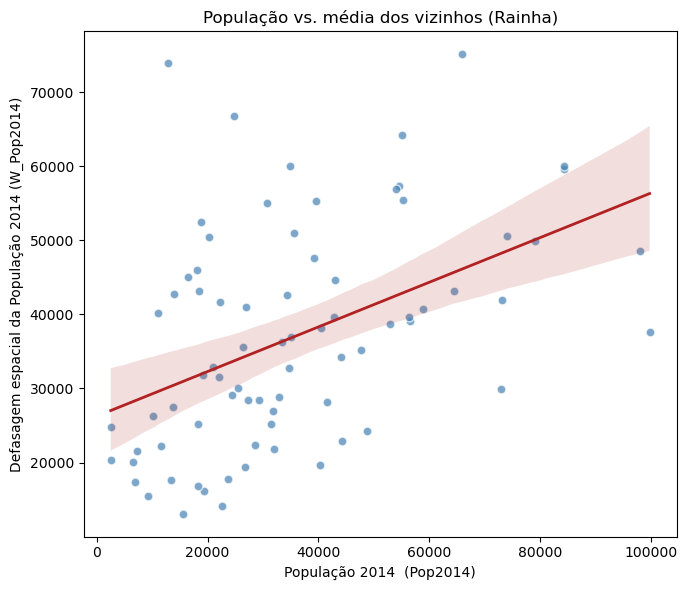

In [28]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.regplot(x=gdf['Pop2014'], y=w_pop_lib, ax=ax,
            scatter_kws=dict(alpha=0.7, s=40, color='steelblue', edgecolor='white'),
            line_kws=dict(color='firebrick', linewidth=2))
ax.set_xlabel('População 2014  (Pop2014)')
ax.set_ylabel('Defasagem espacial da População 2014 (W_Pop2014)')
ax.set_title('População vs. média dos vizinhos (Rainha)')
plt.tight_layout()
plt.show()


## Exercício

Usando os arquivos `RMBH.shp` (recorte territorial da RMBH) e `pratica.csv` (dados):

1. Construa uma matriz de pesos Rainha (Queen) e outra de 4 vizinhos mais próximos (KNN-4).
2. Plote os grafos de vizinhança das duas matrizes lado a lado.
3. Monte uma tabela comparativa com: número de observações, min/max/média/mediana de vizinhos, % de pesos não nulos e número de ilhas.
4. Com a matriz Rainha padronizada em linha, calcule a defasagem espacial da variável `pop` e mostre os 5 primeiros valores (média da população dos vizinhos).

**Dica:** confira o CRS antes de construir a matriz de distância/KNN e use dados projetados.

In [ ]:
# Carrega o território e os dados da prática
rmbh = gpd.read_file('RMBH.shp')
dados = pd.read_csv('pratica.csv')

print('Shapefile:', rmbh.shape, '| CRS:', rmbh.crs)
print('Dados:', dados.shape)
print('Colunas shp:', list(rmbh.columns))
print('Colunas csv:', list(dados.columns))

In [ ]:
# Merge: cod6 (shp) com cod (csv)
gdf_ex = rmbh.merge(dados, left_on='COD6', right_on='cod', how='inner')
print('Após merge:', gdf_ex.shape)
gdf_ex.head()